## Задание 1. Обучите классификатор Random Forest для решения задачи бинарной классификации: для каждого человека научиться предсказывать, выживет ли он при крушении Титаника.

### Устанавливаем зависимости

In [228]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Импортируем датасет

In [229]:
data = pd.read_csv('data/train.csv')

### Производим разведовательный анализ данных

In [230]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [231]:
data.nunique()

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64

In [232]:
data.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


### Сформируем обучающую и тестовую выборки

In [ ]:
from sklearn.model_selection import train_test_split

X, y = data.drop(['Survived'], axis=1), data['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### Feature Engineering

In [234]:
col_drop = ['PassengerId', 'Name', 'Ticket']

X_train = X_train.drop(col_drop, axis=1)
X_test = X_test.drop(col_drop, axis=1)

In [235]:
from sklearn.impute import SimpleImputer #filling missed values

imputer_age = SimpleImputer(strategy='median')
imputer_cabin = SimpleImputer(strategy='most_frequent')

X_train[['Age'] ]= imputer_age.fit_transform(X_train[['Age']])
X_train[['Embarked']] = imputer_cabin.fit_transform(X_train[['Embarked']])

X_test[['Age'] ]= imputer_age.transform(X_test[['Age']])
X_test[['Embarked']] = imputer_cabin.transform(X_test[['Embarked']])

X_train[['Age', 'Embarked']].isna().sum(), X_test[['Age', 'Embarked']].isna().sum()

(Age         0
 Embarked    0
 dtype: int64,
 Age         0
 Embarked    0
 dtype: int64)

In [236]:
X_train['Cabin'] = np.where(X_train['Cabin'].isna(), 0, 1) #processing cabin feature
X_test['Cabin'] = np.where(X_test['Cabin'].isna(), 0, 1)

In [237]:
from sklearn.preprocessing import OneHotEncoder

cat_features_oh = ['Sex', 'Embarked']

encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")

encoded_train = encoder.fit_transform(X_train[cat_features_oh])
encoded_test = encoder.transform(X_test[cat_features_oh])

X_train = pd.concat([X_train.drop(columns=cat_features_oh), encoded_train], axis=1)
X_test = pd.concat([X_test.drop(columns=cat_features_oh), encoded_test], axis=1)

X_train.head(3)

,Pclass,Age,SibSp,Parch,Fare,Cabin,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
692,3,28.5,0,0,56.4958,0,0.0,1.0,0.0,0.0,1.0
481,2,28.5,0,0,0.0000,0,0.0,1.0,0.0,0.0,1.0
527,1,28.5,0,0,221.7792,1,0.0,1.0,0.0,0.0,1.0


In [238]:
X_train.shape, y_train.shape

((712, 11), (712,))

### Построение базовой модели

In [239]:
from sklearn.ensemble import RandomForestClassifier

rfc_simple = RandomForestClassifier()
rfc_simple.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

### Оценка точности модели

              precision    recall  f1-score   support

           0       0.82      0.86      0.84       110
           1       0.76      0.70      0.73        69

    accuracy                           0.80       179
   macro avg       0.79      0.78      0.78       179
weighted avg       0.80      0.80      0.80       179



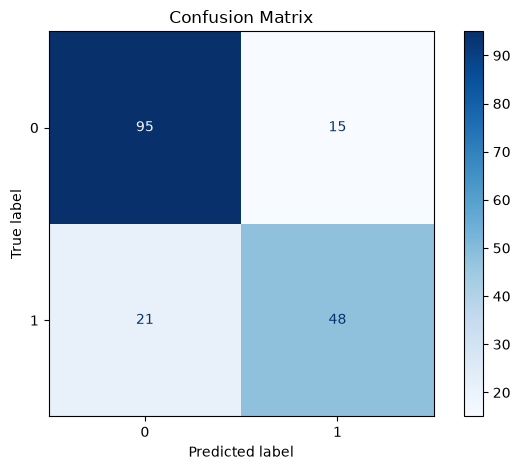

In [241]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

def estimate_model(y_test, y_pred):
    print(classification_report(y_test, y_pred))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
    plt.title(f"Confusion Matrix")
    plt.tight_layout()
    plt.show()

y_pred = rfc_simple.predict(X_test)
estimate_model(y_test, y_pred)

### Настройка гиперпараметров модели

In [242]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

feature_grid = {
    'n_estimators': [60, 100, 140, 180],
    'max_depth': [6, 8, 10, 12],
    'min_samples_split': [2, 3],
}

feature_ranges = {
    'n_estimators': list(range(50, 250)),
    'max_depth': list(range(5, 21)),
    'min_samples_split': list(range(2, 5)),
}

gs = GridSearchCV(RandomForestClassifier(random_state=42), feature_grid, scoring='f1', cv=4)
rs = RandomizedSearchCV(RandomForestClassifier(random_state=42), feature_ranges, n_iter=20, scoring='f1', cv=4, random_state=42)

gs.fit(X_train, y_train)
rs.fit(X_train, y_train)

gs.best_params_, rs.best_params_

({'max_depth': 8, 'min_samples_split': 2, 'n_estimators': 180},
 {'n_estimators': 235, 'min_samples_split': 3, 'max_depth': 10})

### Оценка лучшей модели

In [243]:
rfc_gs = RandomForestClassifier(max_depth=8, min_samples_split=2, n_estimators=180, random_state=42)
rfc_rs = RandomForestClassifier(max_depth=10, min_samples_split=3, n_estimators=235, random_state=42)

rfc_gs.fit(X_train, y_train)
rfc_rs.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",235
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

              precision    recall  f1-score   support

           0       0.79      0.90      0.84       110
           1       0.80      0.62      0.70        69

    accuracy                           0.79       179
   macro avg       0.79      0.76      0.77       179
weighted avg       0.79      0.79      0.79       179



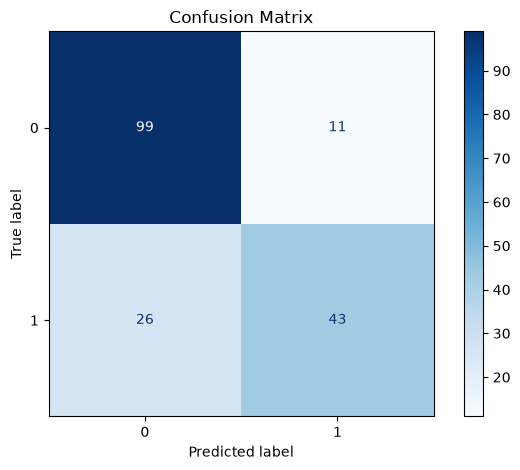

In [244]:
estimate_model(y_test, rfc_gs.predict(X_test))

              precision    recall  f1-score   support

           0       0.80      0.88      0.84       110
           1       0.78      0.65      0.71        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.77       179
weighted avg       0.79      0.79      0.79       179



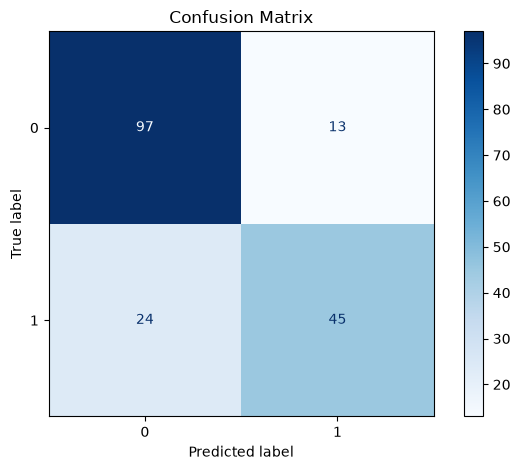

In [245]:
estimate_model(y_test, rfc_rs.predict(X_test))

## Задание 2. Решите задачу из предыдущего пункта используя другие, ранее изученные классификаторы. Сравните их точность предсказания с Random Forest

In [247]:
from sklearn.preprocessing import StandardScaler

num_features = ['Age', 'Fare']

scaler = StandardScaler()
X_train[num_features] = scaler.fit_transform(X_train[num_features])
X_test[num_features] = scaler.transform(X_test[num_features])

CURRENT MODEL IS LGBMClassifier(learning_rate=0.05, max_depth=5, random_state=42)
[LightGBM] [Info] Number of positive: 273, number of negative: 439
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000443 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 214
[LightGBM] [Info] Number of data points in the train set: 712, number of used features: 11
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.383427 -> initscore=-0.475028
[LightGBM] [Info] Start training from score -0.475028
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

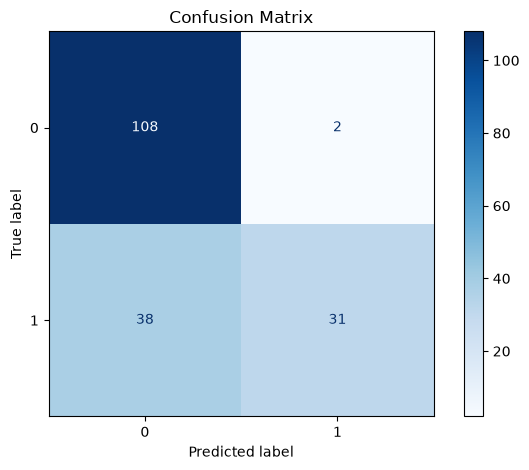

CURRENT MODEL IS LogisticRegression(penalty='l2')
              precision    recall  f1-score   support

           0       0.64      0.98      0.78       110
           1       0.82      0.13      0.23        69

    accuracy                           0.65       179
   macro avg       0.73      0.56      0.50       179
weighted avg       0.71      0.65      0.56       179



/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


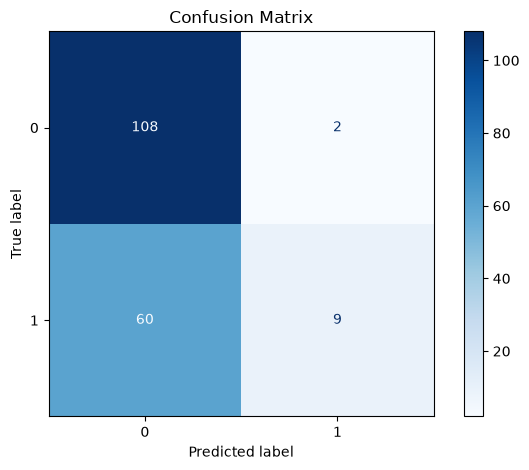

CURRENT MODEL IS GaussianNB()
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       110
           1       0.39      1.00      0.56        69

    accuracy                           0.39       179
   macro avg       0.19      0.50      0.28       179
weighted avg       0.15      0.39      0.21       179



/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

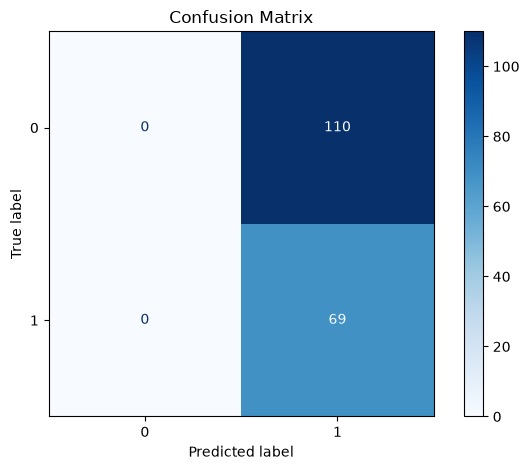

CURRENT MODEL IS KNeighborsClassifier(weights='distance')
              precision    recall  f1-score   support

           0       0.79      0.53      0.63       110
           1       0.51      0.78      0.62        69

    accuracy                           0.63       179
   macro avg       0.65      0.65      0.63       179
weighted avg       0.68      0.63      0.63       179



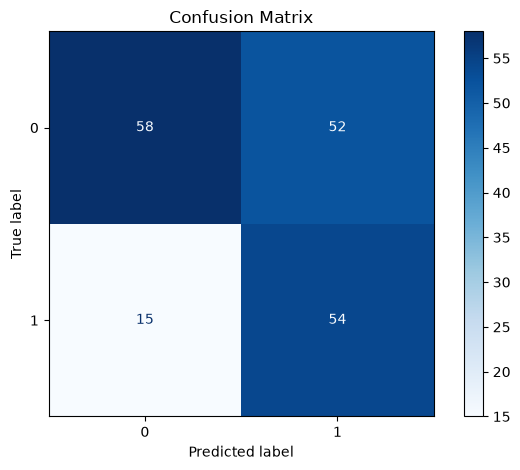

In [250]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    n_estimators=100, 
    learning_rate=0.05, 
    max_depth=5, 
    random_state=42
)

log_reg = LogisticRegression(
    C=1.0, 
    penalty='l2'
)

bayes = GaussianNB()

knn = KNeighborsClassifier(
    n_neighbors=5, 
    weights='distance', )


for model in [lgbm, log_reg, bayes, knn]:
    print(f"CURRENT MODEL IS {model}")
    model.fit(X_train, y_train)
    estimate_model(y_test, model.predict(X_test))